# Apply more and more complex models to the data

In [2]:
import numpy as np
from pathlib import Path
import os, sys
import matplotlib.pyplot as plt
from tqdm.notebook import tqdm
import warnings
from sklearn.model_selection import KFold
import json

repo_root = Path("/home/thardy/elefanto/ConsciousnessTeam_Data/SOUNDMODEL/Data_SoundGOOD/LEAD_ExperimentalFolder")
os.chdir(repo_root)

if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))
os.environ["PYTHONPATH"] = str(repo_root) + os.pathsep + os.environ.get("PYTHONPATH", "")

import LEAD as lead


# Important variables
cwd = Path.cwd()
SNRs = np.array([-np.inf,-13,-11,-9,-7,-5,-3])
SubIDs = ['01','02','03','05','06','07','08','09','11','12','13','14','15','17','19','20','22','23','24','25']
colormap = {0: (0, 0, 0), 1: (0, 0.25, 1), 2: (0, 0.9375, 1), 3: (0, 0.91, 0.1), 4: (1, 0.6, 0), 5: (1, 0, 0), 6: (0.8, 0, 0)}

In [71]:
import json, pickle
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

G_MIN_TRUE = 0.01
G_MIN_FIT = 0.01
THR_QUANTILE = 1
RECOVERED_FILTER = 'relabel'

MODELS = ['Linear', 'GainFixed', 'GainModulated']
MODELS_FIGURE_NAMES = ['Linear', 'FixedGain', 'ModulatedGain']
FIT2TRUE = {'Linear': 'Linear', 'NonLinear1': 'GainFixed', 'GainModulation': 'GainModulated'}
LL_KEYS = {'Linear': 'll_linear_mean', 'NonLinear1': 'll_nonlinear_mean', 'GainModulation': 'll_gainmod_mean'}
WINDOW = {'late': slice(75, 100), 'early': slice(60, 70)}


def load_params(stem):
    stem = Path(stem)
    for p in [stem, *sorted(stem.parent.glob(stem.name + '.*'))]:
        if not p.is_file():
            continue
        if p.suffix == '.npy':
            obj = np.load(p, allow_pickle=True)
            obj = obj.item() if obj.dtype == object else obj
        elif p.suffix == '.npz':
            with np.load(p, allow_pickle=True) as z:
                obj = {k: z[k] for k in z.files}
        elif p.suffix in ('.pkl', '.pickle'):
            with open(p, 'rb') as f:
                obj = pickle.load(f)
        else:
            with open(p) as f:
                obj = json.load(f)
        return {k: float(np.asarray(v)) if np.ndim(v) == 0 else v for k, v in dict(obj).items()}
    raise FileNotFoundError(f"No parameter file for {stem}(.*)")


def max_gain(params, model, n_cat):
    if model == 'GainFixed':
        return abs(params['gain'])
    return max(abs(params.get(f'g{k}', 0.0)) for k in range(1, n_cat))


def frac_below(sim, period, threshold):
    x = np.concatenate([sim[c][:, WINDOW[period]].ravel() for c in sim])
    return float(np.mean(x < threshold))


def is_noticeable(params, model, sim, period, g_min, thr_quantile):
    if model == 'Linear':
        return True
    return max_gain(params, model, len(sim)) >= g_min and frac_below(sim, period, params['threshold']) < thr_quantile


def best_non_null(det):
    fits = list(LL_KEYS)
    return FIT2TRUE[fits[int(np.argmax([det[LL_KEYS[m]] for m in fits]))]]


def load_recovery(root='.', tasks=('Active', 'Passive'), periods=('early', 'late'),
                  g_min_true=G_MIN_TRUE, g_min_fit=G_MIN_FIT, thr_quantile=THR_QUANTILE,
                  recovered_filter=RECOVERED_FILTER):
    rows = []
    for task in tasks:
        for period in periods:
            for true in MODELS:
                ck_path = Path(root) / f"ConfusionMatrix_From_{true}_{task}_{period}.json"
                if not ck_path.exists():
                    print(f"⚠️ missing: {ck_path}")
                    continue
                with open(ck_path) as f:
                    ck = json.load(f)
                folder = Path(root) / "ParameterRecovery" / f"{task}_{period}" / f"From_{true}"
                for det in ck['detailed']:
                    part = det['part']
                    with np.load(folder / f"SimulatedData_part{part}.npz", allow_pickle=False) as z:
                        sim = {int(k): z[k].copy() for k in z.files}

                    true_params = load_params(folder / f"TrueModel_part{part}_params")
                    recovered = best_non_null(det)
                    r = dict(task=task, period=period, true=true, part=part, recovered=recovered,
                             cv_best=det.get('best_cv'))
                    r['true_ok'] = is_noticeable(true_params, true, sim, period, g_min_true, thr_quantile)

                    if recovered == 'Linear':
                        r['recovered_ok'] = True
                    else:
                        fit_params = load_params(folder / f"{recovered}Model_part{part}_params")
                        r['recovered_ok'] = is_noticeable(fit_params, recovered, sim, period, g_min_fit, thr_quantile)
                    r['recovered_filtered'] = recovered if r['recovered_ok'] else (
                        'Linear' if recovered_filter == 'relabel' else None)
                    rows.append(r)
    return rows


def confusion(rows, key, **filt):
    C = np.zeros((len(MODELS), len(MODELS)), int)
    for r in rows:
        if r[key] is not None and all(r[k] == v for k, v in filt.items()):
            C[MODELS.index(r['true']), MODELS.index(r[key])] += 1
    return C


def plot_confusion(C, ax, title):
    P = C / C.sum(1, keepdims=True).clip(min=1)
    im = ax.imshow(P, cmap='Blues', vmin=0, vmax=1)
    for i in range(len(MODELS)):
        for j in range(len(MODELS)):
            ax.text(j, i, f"{P[i, j]:.2f}\n({C[i, j]})", ha='center', va='center',
                    color='white' if P[i, j] > 0.5 else 'black', fontsize=9)
    ax.set_xticks(range(len(MODELS)), MODELS_FIGURE_NAMES, rotation=30, ha='right')
    ax.set_yticks(range(len(MODELS)), MODELS_FIGURE_NAMES)
    ax.set_xlabel('Recovered model')
    ax.set_ylabel('True model')
    ax.set_title(f"{title}\naccuracy = {np.trace(C) / max(C.sum(), 1):.2f}  (N = {C.sum()})", fontsize=10)
    return im


def plot_panels(panels, suptitle, save_path=None):
    fig, axes = plt.subplots(1, len(panels), figsize=(4.8 * len(panels), 4.8), constrained_layout=True)
    for ax, (C, title) in zip(np.atleast_1d(axes), panels):
        im = plot_confusion(C, ax, title)
    fig.colorbar(im, ax=axes, shrink=0.8, label='P(recovered | true)')
    fig.suptitle(suptitle, fontsize=11)
    if save_path:
        fig.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()
    return fig


def report(rows):
    print(f"{'condition':<16}{'true model':<15}{'N':>4}{'true kept':>11}{'recov. not noticeable':>23}")
    for task in sorted({r['task'] for r in rows}):
        for period in sorted({r['period'] for r in rows}):
            for true in MODELS:
                s = [r for r in rows if (r['task'], r['period'], r['true']) == (task, period, true)]
                if s:
                    kept = [r for r in s if r['true_ok']]
                    print(f"{task + ' ' + period:<16}{true:<15}{len(s):>4}{len(kept):>11}"
                          f"{sum(not r['recovered_ok'] for r in kept):>23}")
    print(f"Null won {sum(r['cv_best'] == 'Null' for r in rows)}× (replaced by runner-up)")


def plot_all_confusions(rows, save_prefix=None):
    report(rows)
    sel = [r for r in rows if r['true_ok']]
    sub = None #f"True non-linear models kept if max gain ≥ {G_MIN_TRUE} and threshold < {THR_QUANTILE:.0%} of window data"
    fig1 = plot_panels(
        [(confusion(sel, 'recovered', period='early'), 'Early'),
         (confusion(sel, 'recovered', period='late'), 'Late')],
        sub, save_prefix and f"{save_prefix}_early_late.png")
    fig2 = plot_panels(
        [(confusion(sel, 'recovered'), 'All conditions'),
         (confusion(sel, 'recovered_filtered'),
          f'All conditions, filtered')],
        sub, save_prefix and f"{save_prefix}_filtering.png")
    return fig1, fig2, sel

condition       true model        N  true kept  recov. not noticeable
Active early    Linear           20         20                     11
Active early    GainFixed        20         19                      0
Active early    GainModulated    20         20                      5
Active late     Linear           20         20                      9
Active late     GainFixed        20         20                      1
Active late     GainModulated    20         20                      0
Passive early   Linear           20         20                     17
Passive early   GainFixed        20         20                      5
Passive early   GainModulated    20         19                     13
Passive late    Linear           20         20                     10
Passive late    GainFixed        20         20                      0
Passive late    GainModulated    20         20                      0
Null won 14× (replaced by runner-up)


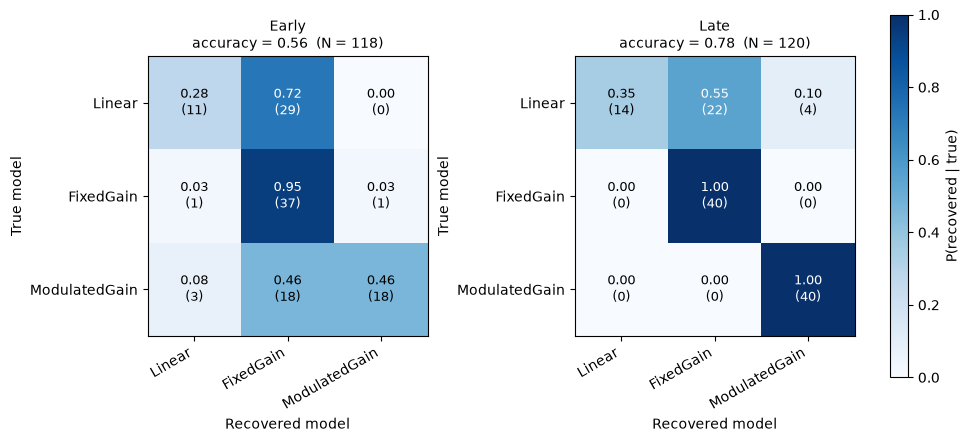

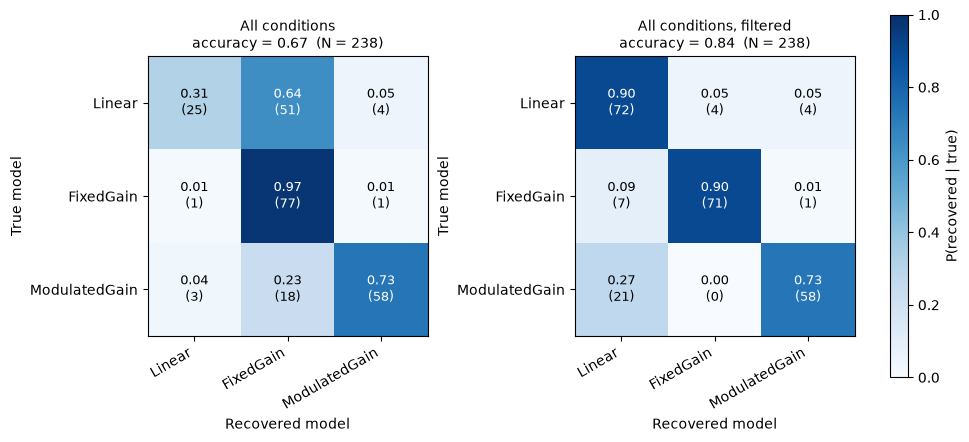

In [72]:
rows = load_recovery(root=repo_root)
fig1, fig2, sel = plot_all_confusions(rows, save_prefix="ConfusionMatrix")

# Control fitted parameters on true data

In [84]:
import re

G_MIN_DATA = 0.01
THR_PCT_MAX = 100
FIT_FILE = {'GainFixed': 'GainFixedModel', 'GainModulated': 'GainModulatedModel'}
TASK_LABEL = {'Passive': 'No-report', 'Active': 'Report'}
MODEL_LABEL = {'GainFixed': 'Fixed Gain', 'GainModulated': 'Modulated Gain'}
MODEL_STYLE = {'GainFixed': dict(marker='s', color='tab:orange'), 'GainModulated': dict(marker='o', color='tab:blue')}
COND_ORDER = [(t, p) for t in ('Passive', 'Active') for p in ('early', 'late')]


def load_window_data(root, task, period, model, part):
    path = Path(root) / "ParameterRecovery" / f"{task}_{period}" / f"From_{model}" / f"SimulatedData_part{part}.npz"
    with np.load(path, allow_pickle=False) as z:
        return np.concatenate([z[k][:, WINDOW[period]].ravel() for k in z.files])


def data_controls(root='.', data_loader=load_window_data):
    out = []
    for task, period in COND_ORDER:
        cv_path = Path(root) / f"5CV_{task}_{period}.json"
        if not cv_path.exists():
            print(f"⚠️ missing: {cv_path}")
            continue
        for part, model in cv_winners(cv_path).items():
            if model not in FIT_FILE:
                continue
            p = load_params(Path(root) / f"Fit_{task}_{period}" / f"{FIT_FILE[model]}_part{part}_params")
            if model == 'GainFixed':
                g = abs(p['gain'])
            else:
                g = max(abs(v) for k, v in p.items() if re.fullmatch(r'g\d+', k) and k != 'g0')
            x = data_loader(root, task, period, model, part)
            out.append(dict(task=task, period=period, part=part, model=model, max_gain=g,
                            threshold=p['threshold'], thr_pct=100 * float(np.mean(x < p['threshold']))))
    return out


def plot_control(res, key, ref, ok, ok_label, ylabel, ylim=None, save_path=None):
    conds = [c for c in COND_ORDER if any((r['task'], r['period']) == c for r in res)]
    rng = np.random.default_rng(0)
    fig, ax = plt.subplots(figsize=(1.8 * len(conds) + 2.2, 4.5), constrained_layout=True)
    for i, (t, p) in enumerate(conds):
        s = [r for r in res if (r['task'], r['period']) == (t, p)]
        for model, st in MODEL_STYLE.items():
            v = [r[key] for r in s if r['model'] == model]
            ax.scatter(i + rng.uniform(-0.2, 0.2, len(v)), v, s=40, alpha=0.8, edgecolor='k', lw=0.5,
                       label=MODEL_LABEL[model] if i == 0 else None, **st)
        ax.text(i, 1.02, f"{sum(ok(r[key]) for r in s)}/{len(s)} {ok_label}", transform=ax.get_xaxis_transform(),
                ha='center', va='bottom', fontsize=9)
    ax.axhline(ref, ls='--', color='k', lw=1)
    if ylim:
        ax.set_ylim(*ylim)
    ax.set_xticks(range(len(conds)), [f"{TASK_LABEL[t]}\n{p}" for t, p in conds])
    ax.set_xlim(-0.6, len(conds) - 0.4)
    ax.set_ylabel(ylabel)
    ax.legend(title='CV winner', frameon=False, loc='upper left', bbox_to_anchor=(1, 1))
    ax.spines[['top', 'right']].set_visible(False)
    if save_path:
        fig.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()

    print(f"{'condition':<18}" + ''.join(f"{MODEL_LABEL[m] + ' ok':>20}" for m in MODEL_STYLE) + "   participants not ok")
    for t, p in conds:
        s = [r for r in res if (r['task'], r['period']) == (t, p)]
        cnt = ''.join(f"{str(sum(ok(r[key]) for r in s if r['model'] == m)) + '/' + str(sum(r['model'] == m for r in s)):>20}"
                      for m in MODEL_STYLE)
        bad = sorted(r['part'] for r in s if not ok(r[key]))
        print(f"{TASK_LABEL[t] + ' ' + p:<18}{cnt}   {bad}")
    return fig


def plot_max_gain_control(res, g_min=G_MIN_DATA, save_path=None):
    return plot_control(res, 'max_gain', g_min, lambda v: v >= g_min, f"≥ {g_min}",
                        'Max non-linear gain (fit on real data)', save_path=save_path)


def plot_threshold_control(res, pct_max=THR_PCT_MAX, save_path=None):
    return plot_control(res, 'thr_pct', pct_max, lambda v: v < pct_max, f"< {pct_max}%",
                        'Inflexion Point percentile in window data (%)', ylim=(-2, 102), save_path=save_path)

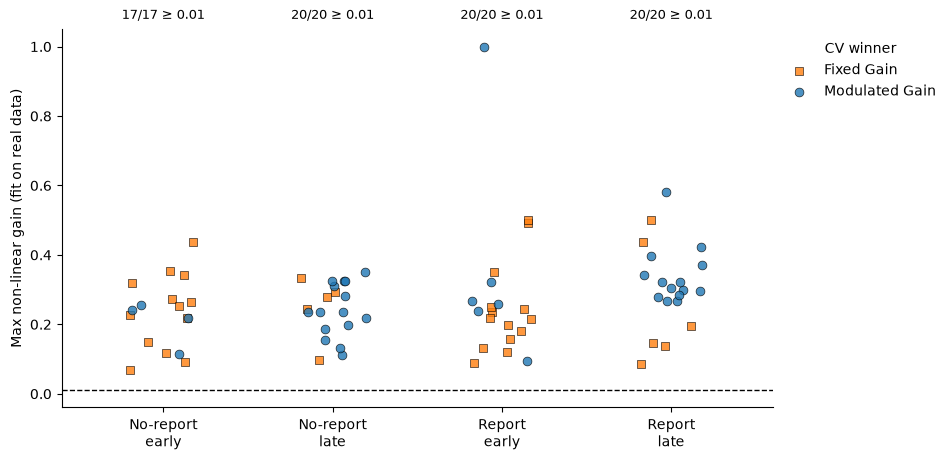

condition                Fixed Gain ok   Modulated Gain ok   participants not ok
No-report early                  13/13                 4/4   []
No-report late                     5/5               15/15   []
Report early                     14/14                 6/6   []
Report late                        6/6               14/14   []


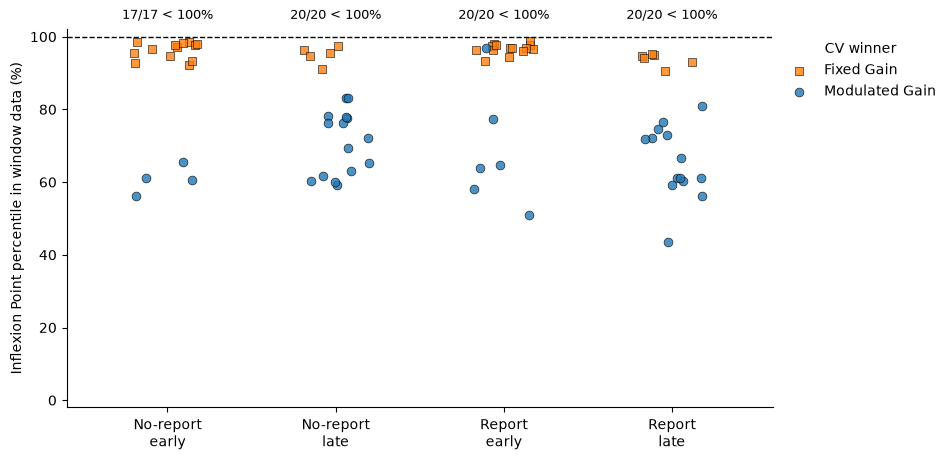

condition                Fixed Gain ok   Modulated Gain ok   participants not ok
No-report early                  13/13                 4/4   []
No-report late                     5/5               15/15   []
Report early                     14/14                 6/6   []
Report late                        6/6               14/14   []


In [86]:
res_ctrl = data_controls(root=repo_root)
fig_gain = plot_max_gain_control(res_ctrl, g_min=0.01)
fig_thr = plot_threshold_control(res_ctrl, pct_max=100)